In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import shap
from lime.lime_tabular import LimeTabularExplainer

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [3]:
PROJECT_DIR = os.path.abspath("..")

DATA_PATH = os.path.join(
    PROJECT_DIR, "data", "cleaned", "ChargingRecords_Featured.csv"
)

MODEL_DIR = os.path.join(PROJECT_DIR, "models")

RESULT_DIR = os.path.join(
    PROJECT_DIR, "results", "explainability"
)

os.makedirs(RESULT_DIR, exist_ok=True)

In [4]:
df = pd.read_csv(DATA_PATH)

regression_model_path = os.path.join(
    MODEL_DIR, "best_regression_model.pkl"
)

reg_model = joblib.load(regression_model_path)

print("Dataset shape:", df.shape)
print("Regression model loaded successfully.")

Dataset shape: (72826, 32)
Regression model loaded successfully.


In [5]:
drop_columns = [
    "Demand",
    "DemandCategory",
    "UserID",
    "ChargerID",
    "StartDay",
    "StartTime",
    "EndDay",
    "EndTime",
    "StartDatetime",
    "EndDatetime",
    "CalculatedDuration",
    "Duration",
    "DurationHours",
    "DurationCategory"
]

X = df.drop(
    columns=drop_columns,
    errors="ignore"
)

y = df["Demand"]

categorical_columns = [
    col for col in X.columns
    if X[col].dtype == "object" or
    str(X[col].dtype) == "category"
]

for col in ["ChargerCompany", "ChargerType", "Location", "TimeOfDay"]:
    if col in X.columns and col not in categorical_columns:
        categorical_columns.append(col)

for col in categorical_columns:
    X[col] = X[col].astype("string")

X = X.replace([np.inf, -np.inf], np.nan)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Categorical columns:", categorical_columns)

Feature shape: (72826, 18)
Target shape: (72826,)
Categorical columns: ['Location', 'ChargerCompany', 'ChargerType']


In [6]:
preprocessor = reg_model.named_steps["preprocessor"]
reg_estimator = reg_model.named_steps["regressor"]

X_transformed = preprocessor.transform(X)

if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

X_transformed = np.asarray(X_transformed)

print("Transformed shape:", X_transformed.shape)
print("Number of features:", len(feature_names))

Transformed shape: (72826, 33)
Number of features: 33


In [7]:
rng = np.random.default_rng(42)

background_size = min(100, len(X_transformed))
explanation_size = min(200, len(X_transformed))

background_indices = rng.choice(
    len(X_transformed),
    size=background_size,
    replace=False
)

explanation_indices = rng.choice(
    len(X_transformed),
    size=explanation_size,
    replace=False
)

background_data = X_transformed[background_indices]
explanation_data = X_transformed[explanation_indices]

print("Background sample:", background_data.shape)
print("Explanation sample:", explanation_data.shape)

Background sample: (100, 33)
Explanation sample: (200, 33)


,Feature,Importance
7,num__Minute,491
6,num__Hour,296
2,num__Day,257
4,num__WeekOfYear,246
10,num__HourCos,177
9,num__HourSin,167
29,cat__ChargerCompany_0,120
3,num__DayOfWeek,119
12,num__MonthCos,111
31,cat__ChargerType_0,101


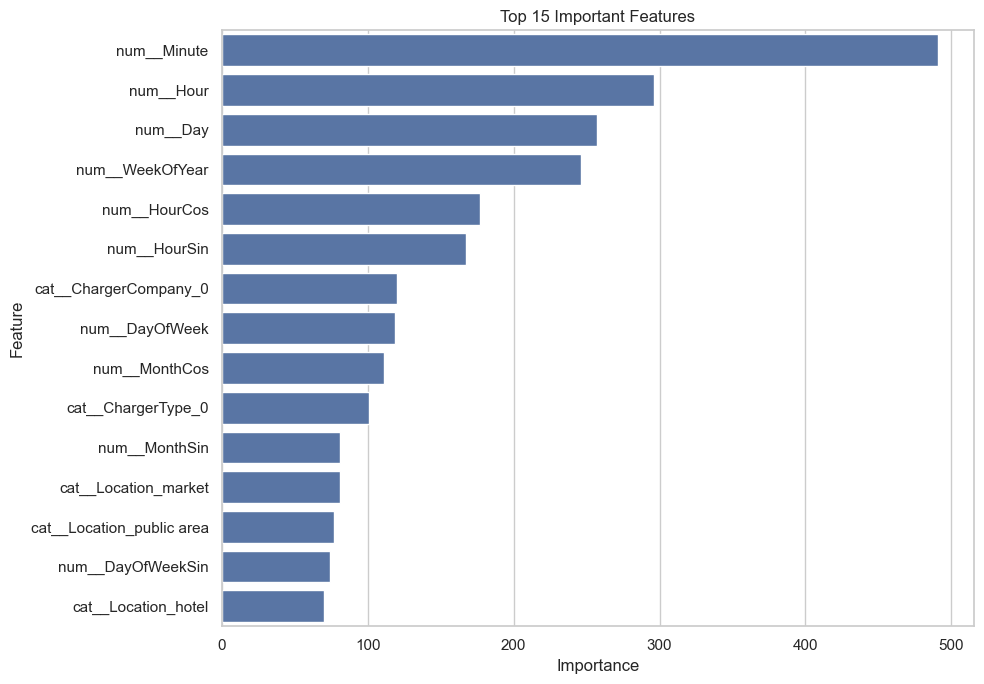

In [8]:
if hasattr(reg_estimator, "feature_importances_"):
    importance_values = reg_estimator.feature_importances_

elif hasattr(reg_estimator, "coef_"):
    importance_values = np.abs(
        np.asarray(reg_estimator.coef_)
    ).flatten()

else:
    importance_values = None

if importance_values is not None:

    feature_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    })

    feature_importance = feature_importance.sort_values(
        by="Importance",
        ascending=False
    )

    display(feature_importance.head(20))

    feature_importance.to_csv(
        os.path.join(RESULT_DIR, "feature_importance.csv"),
        index=False
    )

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=feature_importance.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULT_DIR, "feature_importance.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("The selected model does not provide built-in feature importance.")

In [ ]:
# Create SHAP Explainer

shap_explainer = shap.Explainer(
    reg_estimator,
    background_data,
    feature_names=feature_names
)

shap_values = shap_explainer(
    explanation_data,
    check_additivity=False
)

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_values.values.shape)

SHAP values calculated successfully.
SHAP values shape: (200, 33)


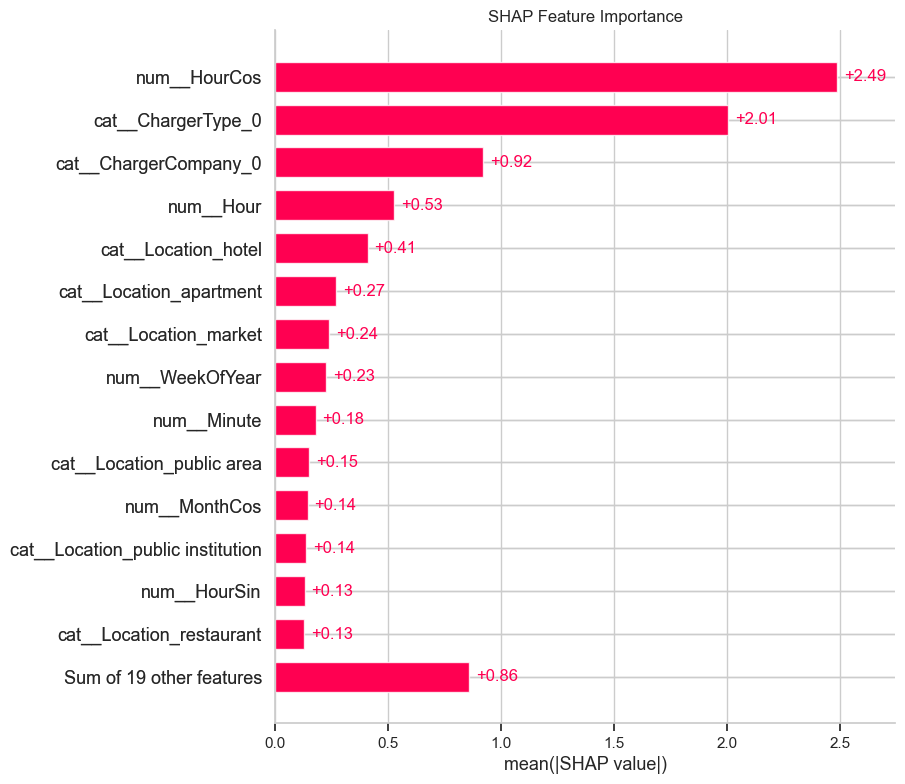

In [11]:
plt.figure()

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title("SHAP Feature Importance")

plt.savefig(
    os.path.join(RESULT_DIR, "shap_bar_plot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

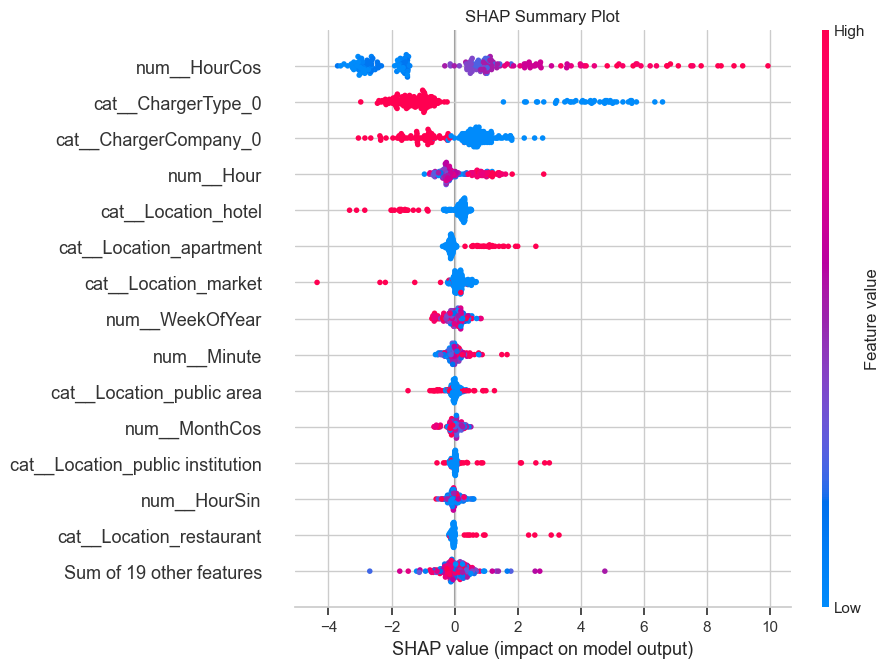

In [12]:
plt.figure()

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot")

plt.savefig(
    os.path.join(RESULT_DIR, "shap_beeswarm_plot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Most influential feature: num__HourCos


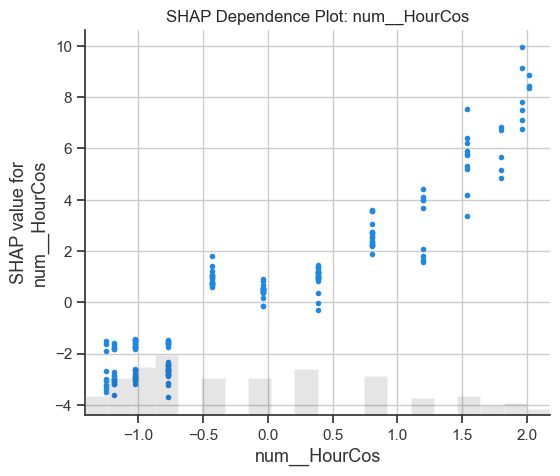

In [13]:
mean_shap = np.abs(shap_values.values).mean(axis=0)

top_feature_index = np.argmax(mean_shap)

top_feature_name = feature_names[top_feature_index]

print("Most influential feature:", top_feature_name)

shap.plots.scatter(
    shap_values[:, top_feature_index],
    show=False
)

plt.title(f"SHAP Dependence Plot: {top_feature_name}")

plt.savefig(
    os.path.join(RESULT_DIR, "shap_dependence_plot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
lime_explainer = LimeTabularExplainer(
    training_data=background_data,
    feature_names=list(feature_names),
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer initialized successfully.")

LIME explainer initialized successfully.


In [15]:
sample_index = 0

lime_explanation = lime_explainer.explain_instance(
    data_row=explanation_data[sample_index],
    predict_fn=reg_estimator.predict,
    num_features=10
)

print("Actual Demand:", y.iloc[explanation_indices[sample_index]])

print(
    "Predicted Demand:",
    reg_estimator.predict(
        explanation_data[sample_index].reshape(1, -1)
    )[0]
)

print("\nLIME Explanation:")
display(pd.DataFrame(
    lime_explanation.as_list(),
    columns=["Feature", "Contribution"]
))

Actual Demand: 31.19
Predicted Demand: 19.299814765600523

LIME Explanation:


,Feature,Contribution
0,cat__Location_camping <= 0.00,-4.930883
1,cat__ChargerType_0 <= 0.00,4.477254
2,0.00 < cat__ChargerCompany_0 <= 1.00,-1.968055
3,-1.03 < num__HourCos <= -0.43,-1.910995
4,cat__Location_market <= 0.00,1.428093
5,cat__Location_hotel <= 0.00,1.172932
6,cat__Location_apartment <= 0.00,-1.153853
7,cat__Location_golf <= 0.00,-1.021634
8,cat__Location_restaurant <= 0.00,-0.994059
9,cat__Location_public parking lot > 0.00,-0.667653


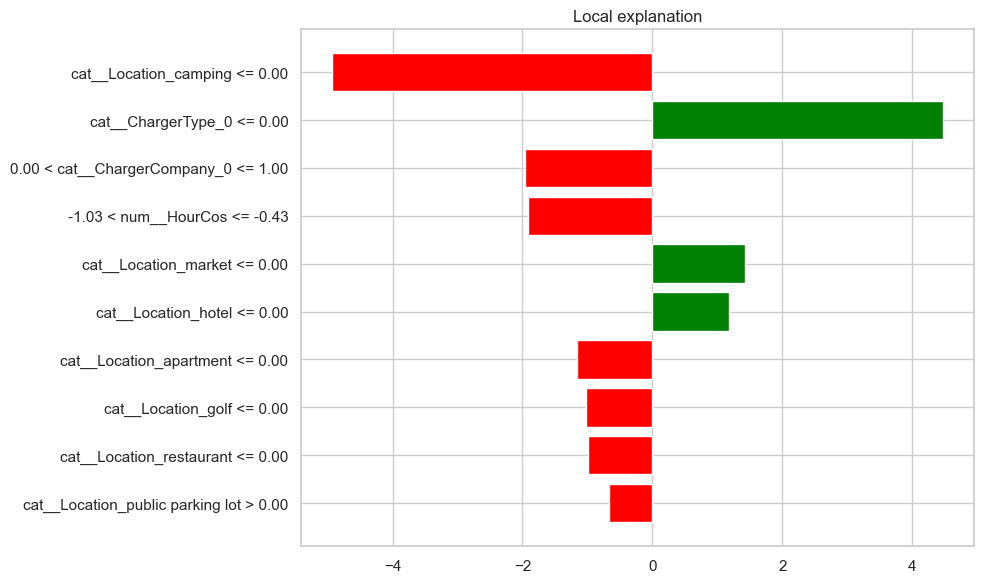

In [16]:
lime_figure = lime_explanation.as_pyplot_figure()

lime_figure.set_size_inches(10, 6)
lime_figure.tight_layout()

lime_figure.savefig(
    os.path.join(RESULT_DIR, "lime_explanation.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
lime_html_path = os.path.join(
    RESULT_DIR,
    "lime_explanation.html"
)

lime_explanation.save_to_file(lime_html_path)

print("LIME explanation saved:", lime_html_path)

LIME explanation saved: c:\Users\yendl\OneDrive\Documents\GUVI Folder\ev-charging_project\results\explainability\lime_explanation.html


In [18]:
summary = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
})

summary = summary.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

summary.to_csv(
    os.path.join(RESULT_DIR, "shap_feature_summary.csv"),
    index=False
)

display(summary.head(15))

print("\nExplainability analysis completed.")
print("Results saved in:", RESULT_DIR)

,Feature,Mean_Absolute_SHAP
10,num__HourCos,2.489521
31,cat__ChargerType_0,2.006236
29,cat__ChargerCompany_0,0.921471
6,num__Hour,0.526673
21,cat__Location_hotel,0.410841
16,cat__Location_apartment,0.270829
22,cat__Location_market,0.239443
4,num__WeekOfYear,0.226320
7,num__Minute,0.181199
23,cat__Location_public area,0.151484



Explainability analysis completed.
Results saved in: c:\Users\yendl\OneDrive\Documents\GUVI Folder\ev-charging_project\results\explainability
